# 02 · Поля бланка: определения, единицы и отказ до модели

## tl;dr

Измерения v1 сохранены. Minute-range включает акцелерации и не является автоматически амплитудой конкретного прибора. Добавлен train-only probe с исключением событий; новый descriptor не объявляется эталоном. Для новых моделей — одна единица на величину и строгий отказ при неполном/неподтверждённом входе.

Глубокая подготовка v1 сохранена ниже; reference scalers не используются новыми строгими классификаторами.


## Context & Methods

### Key Assumptions

- Приложение дородовое; анализ в родах и клинические пороги из таких работ нельзя автоматически переносить. У JNU бинарная **экспертная FIGO**, не три класса и не диагноз гипоксии.
- 30-минутные записи 4 Hz и фиксированные patient-component splits из 01 сохраняются. Формулы заданы до анализа; графики, чувствительность и опубликованные сравнения — **только train**. Test лишь преобразуется фиксированным кодом и проверяется на целостность.
- Собственная базальная линия — медиана/итеративное отсечение, **не клон Mantel, WMFB, SisPorto или Dawes–Redman**. JNU не содержит экспертной разметки baseline/events; синтетические проверки оценивают код, а не медицинскую точность.
- Заполняются только внутренние разрывы ≤2 s, временная ось сохраняется. Неизвестное ≠ нормальное ≠ ноль. Полные события и цензурированные кандидаты различаются.
- LTV-минуты: >75% исходных наблюдений, без части децелерации. STV дополнительно требует полных эпох после краткого заполнения и ≥80% наблюдавшихся точек в каждой эпохе. Эти дополнительные ограничения — инженерная версия v1.
- Набор полей отчёта определяет отдельную модель. Энтропия, спектр, площади/длительности событий и скрытые временные параметры недоступны, если их нет на бланке. Они не входят в основные report profiles.
- median imputer + RobustScaler fit только по train с заранее заданной минимальной поддержкой; маски всех колонок сохраняются. В CV обязательно fit необученный шаблон заново внутри каждого fit-fold. CatBoost использует значения без масштабирования.
- 10/17/20-минутные префиксы — анализ устойчивости. Полная FIGO-метка **не приписывается** короткому окну: оно может содержать другую картину КТГ.

In [3]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.features.jnu_ctg_report_extraction import *
from src.features.jnu_ctg_report_analysis import (export_preprocessing,train_sensitivity,
    compare_published_train,example_report_outputs,validate_exports,write_contracts,MODELS)
from src.features.ctg_russian_reports import EXAMPLE_TEXT,FIELDS
sns.set_theme(style='whitegrid',font_scale=1.)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_colwidth',85)
OUT.mkdir(parents=True,exist_ok=True)
def show_save(name):
    plt.gcf().savefig(OUT/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · воспроизводимое извлечение всех записей

Источник: [JNU-CTG 1.0.0](https://zenodo.org/records/21800730). Исходные CRC/SHA и связи с patient_id проверены в 01. Код ниже читает memory-map исходных FHR/UC и сохраняет собственные признаки отдельно от подготовки 01. Кеш принимается только при совпадении кода, конфигурации, source manifest и хешей созданных файлов. Никакие опубликованные NetFea/F_STV не используются для настройки экстрактора.

Инженерное `report_quality_eligible`: ≥80% наблюдаемого FHR, ≥80% покрытия рассчитанной базальной линией и ≥5 пригодных STV-минут. Это **не клиническая пригодность** и не доказанное достаточное время исследования. В 02 он задаёт только fit-когорту reference scaler. Это не автоматическая рекомендация удалить остальные записи из обучения/оценки классификатора. Все строки остаются в X; причины отсутствия STV могут зависеть от децелераций, поэтому сам отбор способен смещать классы. В будущем отказ модели включается в знаменатель охвата.

In [5]:
measurements=extract_dataset()
splits=pd.read_parquet(SOURCE/'splits.parquet')
index=pd.read_parquet(SOURCE/'signal_index.parquet')
signals=np.load(SOURCE/'signals_original_float32.npy',mmap_mode='r')
train=measurements.merge(splits.loc[splits.split=='train',['record_id','patient_id','patient_component']],on='record_id',validate='one_to_one')
profiles=export_preprocessing(measurements)
display(profiles)
support=pd.DataFrame({'records':[len(train)],'patients':[train.patient_id.nunique()],
    'quality_rule_pass':[train.report_quality_eligible.sum()],
    'no_usable_STV_minute':[(train.eligible_stv_min==0).sum()],
    'censored_event_candidates':[(train.event_censored_candidates>0).sum()]})
support.to_csv(OUT/'train_support.csv',index=False)
display(support)
q=splits.loc[splits.split=='train',['record_id','figo_label']].merge(measurements[['record_id','report_quality_eligible']],on='record_id',validate='one_to_one')
quality_by_label=q.groupby('figo_label').agg(records=('record_id','size'),reference_fit_records=('report_quality_eligible','sum'),reference_fit_fraction=('report_quality_eligible','mean'))
quality_by_label.to_csv(OUT/'train_quality_by_label.csv')
display(quality_by_label.round(3))
print('All rows retained:',measurements.shape,'; target columns in X: none')


All rows retained: (20769, 66) ; target columns in X: none


,profile,report_inputs,with_missing_masks,fit_train_records,constant_train_fields
0,minimal,3,6,10391,
1,variability,5,10,10391,
2,sonomed_fields,13,26,10391,duration_min
3,mfmon_fields,10,20,10391,duration_min
4,mak_fields,8,16,10391,duration_min


,records,patients,quality_rule_pass,no_usable_STV_minute,censored_event_candidates
0,12464,7564,10391,22,5445


,records,reference_fit_records,reference_fit_fraction
figo_label,,,
0.0,5756,5189,0.901
1.0,6708,5202,0.775


### Что доступно в вашем примере

18 полей в переписанном примере — это значения в двух единицах вместе с длительностью и качеством; они не являются 18 независимыми физиологическими характеристиками. Таблица различает воспроизводимую формулу, неизвестную формулу прибора и отсутствие нужного канала. Неизвестные поля JNU экспортируются как NaN.

In [7]:
mapping=pd.DataFrame([
    ['Время / потери сигнала','duration_min / signal_loss_pct','вычисляется','маска прибора может отличаться'],
    ['Базальная ЧСС','baseline_bpm','приближение','собственная базальная линия'],
    ['AC10, AC15, DC15','acc10 / acc15 / dec15','приближение','сегментация и категория AC10'],
    ['Децелерации ≥20 ударов','dec20lost_count','приближение','площадь относительно базальной линии'],
    ['STV мс / BPM','stv_ms / stv_bpm','формула + маски v1','3.75 s; отдельный вариант 4 s'],
    ['Амплитуда мс / BPM','amplitude_ms / amplitude_bpm','формула + маски v1','минутный размах; не размах всей КТГ'],
    ['Высокая / низкая вариабельность','sonomed / mfmon / dr candidates','правило + оценки v1','разные пороги и длительности'],
    ['Частота осцилляций','osc_* diagnostics','исследовательский proxy','плавающая линия/фильтры неизвестны'],
    ['Синусоидальный ритм, min','sinusoidal_min','недоступно','спектральная полоса не диагноз'],
    ['ВКИ, ms / BPM','vstv_ms','недоступно','нужны истинные интервалы и формула'],
    ['Частота шевелений','movements_per_hour','недоступно','нет актограммы/маркера'],
    ['ПСП, баллы, итоговые критерии','excluded_conclusions','не predictor','выход другой системы/заключение'],
],columns=['Поле бланка','Столбец / семейство','Статус','Ограничение'])
mapping.to_csv(OUT/'report_field_mapping.csv',index=False)
display(mapping)


,Поле бланка,Столбец / семейство,Статус,Ограничение
0,Время / потери сигнала,duration_min / signal_loss_pct,вычисляется,маска прибора может отличаться
1,Базальная ЧСС,baseline_bpm,приближение,собственная базальная линия
2,"AC10, AC15, DC15",acc10 / acc15 / dec15,приближение,сегментация и категория AC10
3,Децелерации ≥20 ударов,dec20lost_count,приближение,площадь относительно базальной линии
4,STV мс / BPM,stv_ms / stv_bpm,формула + маски v1,3.75 s; отдельный вариант 4 s
5,Амплитуда мс / BPM,amplitude_ms / amplitude_bpm,формула + маски v1,минутный размах; не размах всей КТГ
6,Высокая / низкая вариабельность,sonomed / mfmon / dr candidates,правило + оценки v1,разные пороги и длительности
7,Частота осцилляций,osc_* diagnostics,исследовательский proxy,плавающая линия/фильтры неизвестны
8,"Синусоидальный ритм, min",sinusoidal_min,недоступно,спектральная полоса не диагноз
9,"ВКИ, ms / BPM",vstv_ms,недоступно,нужны истинные интервалы и формула


## Results · базальная линия, события и маски на train

Примеры выбраны из train по рассчитанным дескрипторам для проверки трёх разных ситуаций, без клинических меток. Цветные участки — найденные полные события; штриховка — пропуски. Это техническая визуальная проверка правдоподобия, не экспертная разметка точности. Кандидат у пропуска/края не считается завершённым событием.

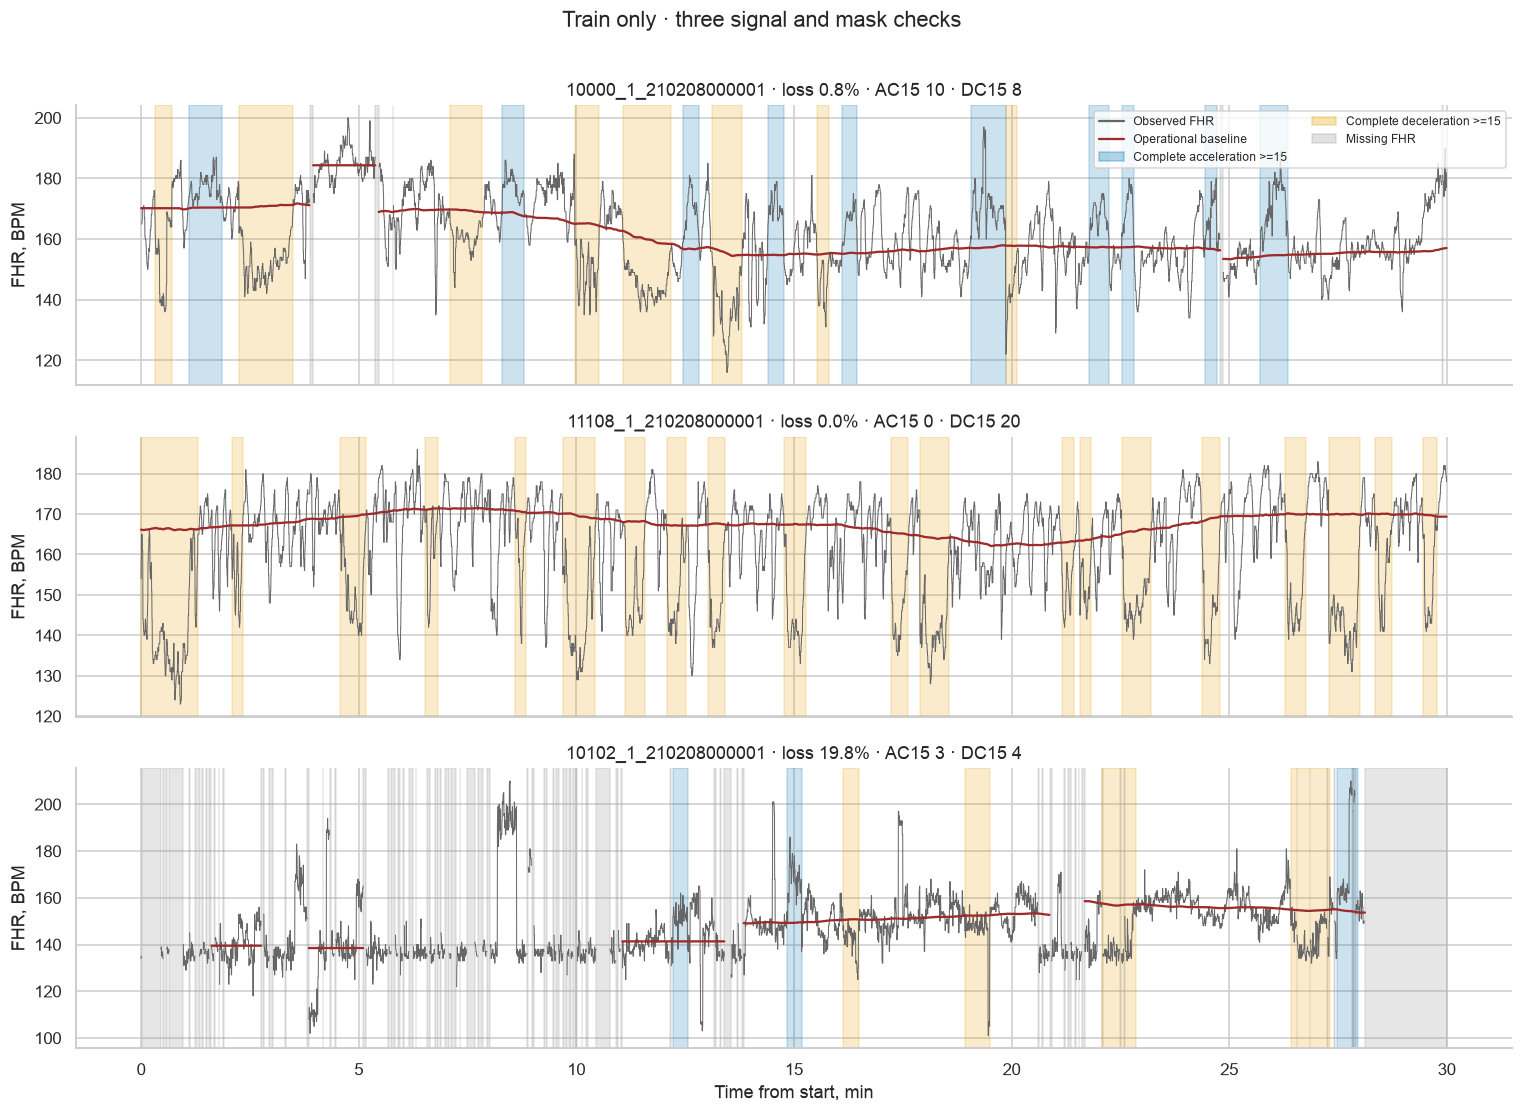

In [9]:
eligible=train[train.report_quality_eligible].copy()
examples=[eligible.sort_values('record_id').iloc[0].record_id,
    eligible.sort_values('dec15_count',ascending=False).iloc[0].record_id,
    train.loc[train.signal_loss_pct.between(15,30)].sort_values('record_id').iloc[0].record_id]
fig,axes=plt.subplots(3,1,figsize=(14,10),sharex=True)
for ax,record in zip(axes,examples):
    pos=int(index.set_index('record_id').loc[record,'signal_row'])
    f,ev,m,d=extract_report_features(signals[pos],diagnostics=True)
    time=np.arange(7200)/240
    ax.plot(time,np.where(d['observed'],signals[pos,:,0],np.nan),color='#666666',lw=.65,label='FHR observed')
    ax.plot(time,d['baseline'],color='#9e2a2b',lw=1.5,label='Operational baseline')
    for a,b in runs(~d['observed']):ax.axvspan(a/240,b/240,color='#9e9e9e',alpha=.25)
    for event in ev.itertuples():
        if not event.censored and event.peak_bpm>=15:
            ax.axvspan(event.start_s/60,event.end_s/60,color='#0072b2' if event.kind=='acceleration' else '#e69f00',alpha=.2)
    ax.set(title=f'{record} · loss {f["signal_loss_pct"]:.1f}% · AC15 {f["acc15_count"]:.0f} · DC15 {f["dec15_count"]:.0f}',ylabel='FHR, BPM')
axes[0].legend(handles=[Line2D([],[],color='#666666',label='Observed FHR'),
    Line2D([],[],color='#9e2a2b',label='Operational baseline'),
    Patch(color='#0072b2',alpha=.3,label='Complete acceleration >=15'),
    Patch(color='#e69f00',alpha=.3,label='Complete deceleration >=15'),
    Patch(color='#9e9e9e',alpha=.3,label='Missing FHR')],loc='upper right',fontsize=8,ncol=2)
axes[-1].set_xlabel('Time from start, min')
fig.suptitle('Train only · three signal and mask checks',y=1.01)
fig.tight_layout();show_save('01_signal_event_checks.png')


### Распределения и поддержка измерений

Распределения строятся по исходным значениям без winsorization и без заполнения NaN. Большие значения не удаляются только потому, что необычны. Каждый график показывает число реально рассчитанных значений. Недостаток пригодных минут должен быть виден рядом со STV.

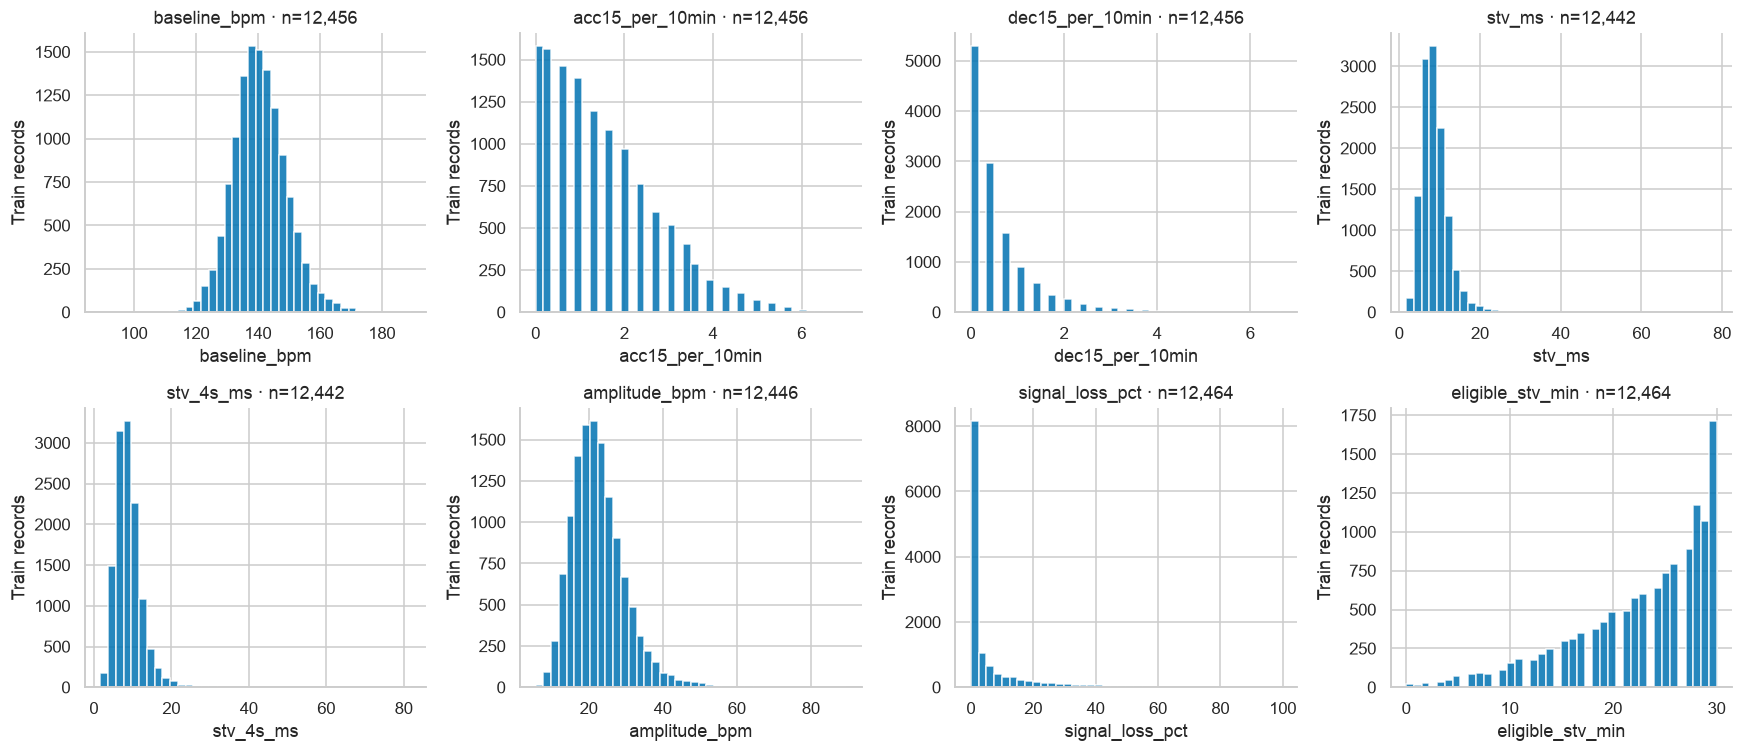

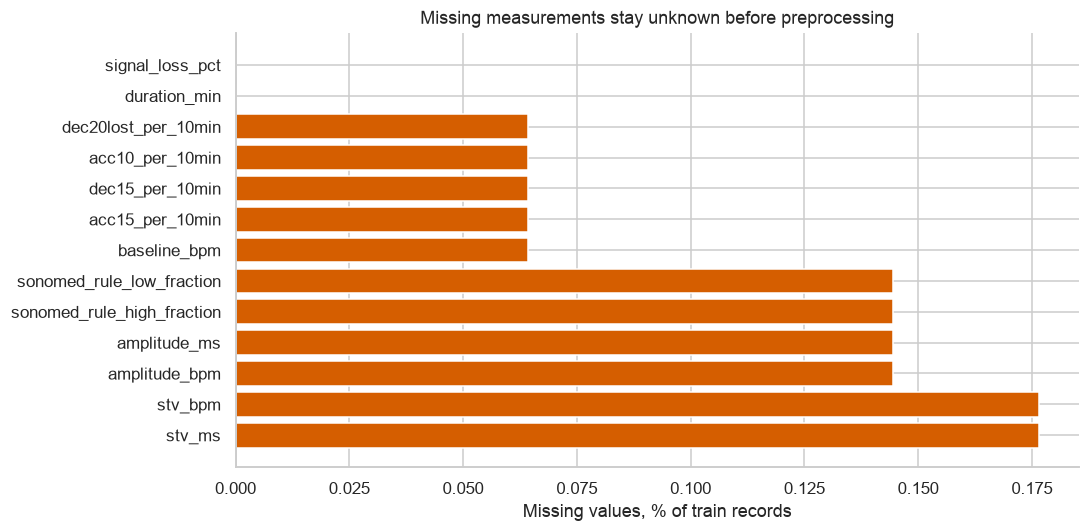

,eligible_stv_min,event_censored_candidates,signal_loss_pct,adjacent_jump_gt25_fraction
count,12464.000,12464.000,12464.000,12464.000
mean,22.876,0.727,5.685,0.001
std,6.560,1.084,11.281,0.001
min,0.000,0.000,0.000,0.000
25%,19.000,0.000,0.028,0.000
50%,25.000,0.000,0.722,0.000
75%,28.000,1.000,5.486,0.001
max,30.000,10.000,99.542,0.025


In [11]:
cols=['baseline_bpm','acc15_per_10min','dec15_per_10min','stv_ms','stv_4s_ms','amplitude_bpm','signal_loss_pct','eligible_stv_min']
fig,axes=plt.subplots(2,4,figsize=(16,7))
for ax,col in zip(axes.flat,cols):
    values=train[col].dropna()
    ax.hist(values,bins=40,color='#0072b2',alpha=.85)
    ax.set(title=f'{col} · n={len(values):,}',xlabel=col,ylabel='Train records')
fig.tight_layout();show_save('02_train_distributions.png')
needed=list(dict.fromkeys(c for p in PROFILE_FIELDS.values() for c in p))
available=pd.concat([train[['record_id']],profile_frame(train,'sonomed_fields')],axis=1)
missing=available.drop(columns='record_id').isna().mean().sort_values(ascending=False)
missing.to_csv(OUT/'train_report_missingness.csv',header=['missing_fraction'])
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(missing.index,missing.values*100,color='#d55e00')
ax.set(xlabel='Missing values, % of train records',title='Missing measurements stay unknown before preprocessing')
fig.tight_layout();show_save('03_missing_measurements.png')
display(train[['eligible_stv_min','event_censored_candidates','signal_loss_pct','adjacent_jump_gt25_fraction']].describe().round(3))


### Чувствительность к способу расчёта · 128 независимых train-компонент

Пример из каждой компоненты выбирается по стабильному порядку ID, затем случайная выборка с фиксированным seed. Это не «первая по времени» запись. Сравниваются 11 настроек: семейство/окно базальной линии, заполнение 0/1/2 s, полоса возврата и сглаживание событий. Основная настройка задана заранее и **не выбирается по FIGO**. Таблица показывает изменение измерений на одних записях; это не MAE относительно медицинского эталона.

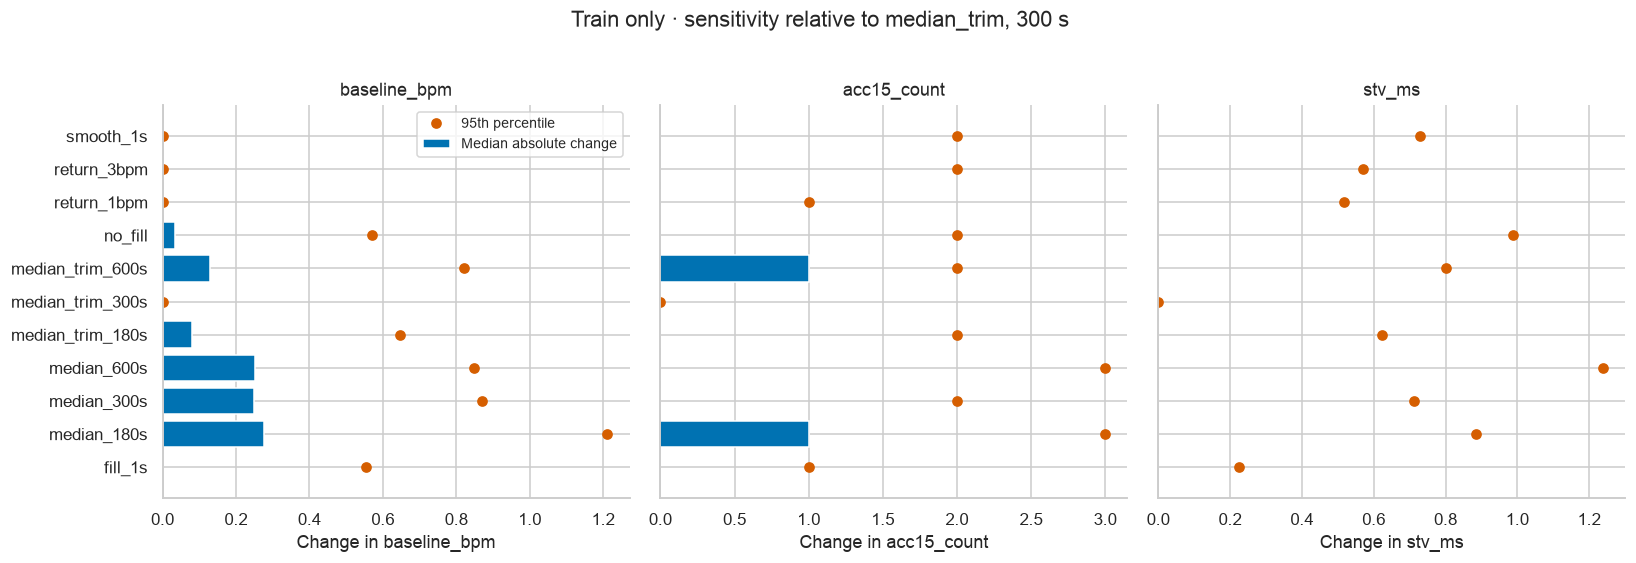

feature,acc15_count,baseline_bpm,stv_ms
recipe,,,
fill_1s,1.0,0.554,0.225
median_180s,3.0,1.211,0.886
median_300s,2.0,0.870,0.713
median_600s,3.0,0.849,1.239
median_trim_180s,2.0,0.646,0.624
median_trim_300s,0.0,0.000,0.000
median_trim_600s,2.0,0.822,0.801
no_fill,2.0,0.570,0.987
return_1bpm,1.0,0.000,0.519


In [13]:
sensitivity,duration,delta_summary=train_sensitivity(measurements,sample_size=128)
chosen=['baseline_bpm','acc15_count','stv_ms']
fig,axes=plt.subplots(1,3,figsize=(15,5),sharey=True)
for ax,col in zip(axes,chosen):
    part=delta_summary[delta_summary.feature==col].set_index('recipe')
    ax.barh(part.index,part.median_absolute_change,color='#0072b2',label='Median absolute change')
    ax.plot(part.p95_absolute_change,part.index,'o',color='#d55e00',label='95th percentile')
    ax.set(xlabel=f'Change in {col}',title=col)
axes[0].legend(fontsize=9);fig.suptitle('Train only · sensitivity relative to median_trim, 300 s',y=1.02)
fig.tight_layout();show_save('04_recipe_sensitivity.png')
display(delta_summary[delta_summary.feature.isin(chosen)].pivot(index='recipe',columns='feature',values='p95_absolute_change').round(3))


### Длительность исследования и разные эпизоды вариабельности

17 min взяты из примера пользователя. Нормирование числа событий по длительности устраняет только арифметическую разницу знаменателя; оно не возвращает пропущенный эпизод активности. Полная 30-минутная запись JNU не доказывает качество модели на 17-минутном бланке. Префиксы сохраняются без новых target-меток.

Правила эпизодов на графике используют одну и ту же собственную минутную LTV. Поэтому различия вызваны определениями даже до дополнительной разницы приборов. D/R-кандидат не включает гестационное подтверждение.

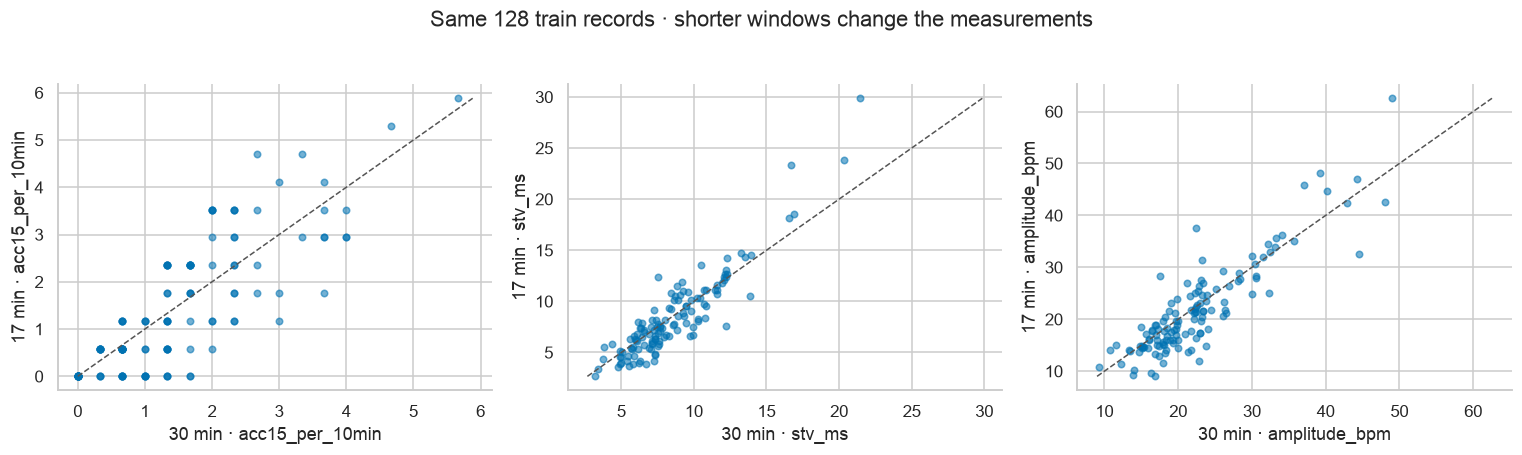

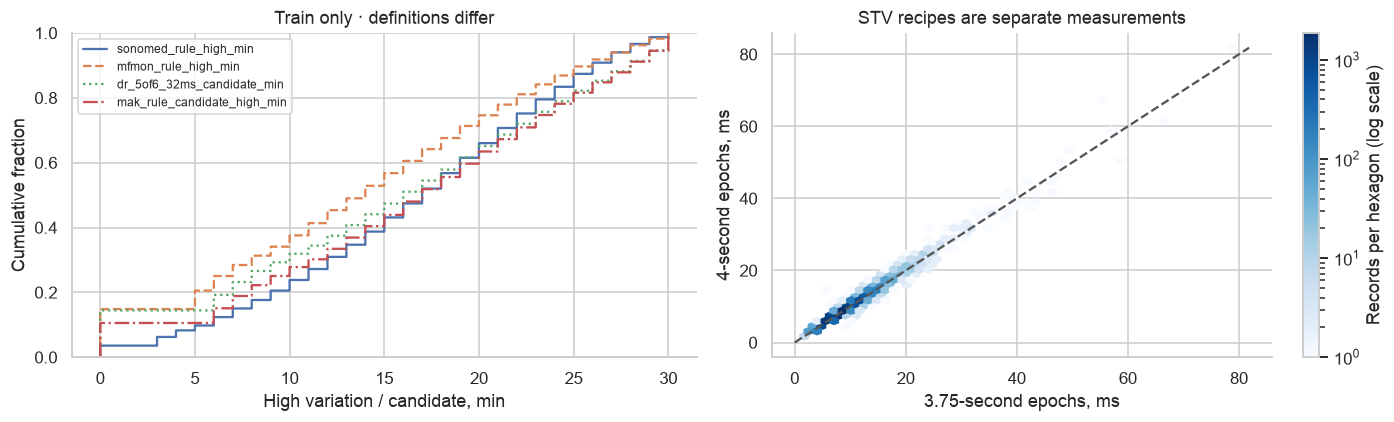

,sonomed_rule_high_min,mfmon_rule_high_min,dr_5of6_32ms_candidate_min,mak_rule_candidate_high_min
count,12446.00,12446.00,12446.00,12446.00
median,17.00,14.00,16.00,17.00
mean,16.41,13.65,15.52,16.33


In [15]:
reference=duration.query('prefix_min==30').set_index('record_id')
short=duration.query('prefix_min==17').set_index('record_id')
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,col in zip(axes,['acc15_per_10min','stv_ms','amplitude_bpm']):
    ax.scatter(reference[col],short[col],alpha=.55,s=18,color='#0072b2')
    vals=pd.concat([reference[col],short[col]]).dropna()
    if len(vals):ax.plot([vals.min(),vals.max()],[vals.min(),vals.max()],'--',color='#555555',lw=1)
    ax.set(xlabel=f'30 min · {col}',ylabel=f'17 min · {col}')
fig.suptitle('Same 128 train records · shorter windows change the measurements',y=1.03)
fig.tight_layout();show_save('05_duration_sensitivity.png')
episode_cols=['sonomed_rule_high_min','mfmon_rule_high_min','dr_5of6_32ms_candidate_min','mak_rule_candidate_high_min']
fig,axes=plt.subplots(1,2,figsize=(13,4))
for col,style in zip(episode_cols,['-','--',':','-.']):
    sns.ecdfplot(data=train,x=col,ax=axes[0],label=col,linestyle=style)
axes[0].legend(fontsize=8);axes[0].set(xlabel='High variation / candidate, min',ylabel='Cumulative fraction',title='Train only · definitions differ')
valid=train[['stv_ms','stv_4s_ms']].dropna()
hexplot=axes[1].hexbin(valid.stv_ms,valid.stv_4s_ms,gridsize=50,mincnt=1,cmap='Blues',norm=LogNorm())
fig.colorbar(hexplot,ax=axes[1],label='Records per hexagon (log scale)')
lims=[0,max(valid.max())];axes[1].plot(lims,lims,'--',color='#555555')
axes[1].set(xlabel='3.75-second epochs, ms',ylabel='4-second epochs, ms',title='STV recipes are separate measurements')
fig.tight_layout();show_save('06_variability_definitions.png')
display(train[episode_cols].agg(['count','median','mean']).round(2))


### Опубликованные признаки — сравнение, не эталон прибора

Официальные F_BL/F_A_N/F_D_N/F_STV/F_LTV сравниваются только на train. В выпущенном архиве нет полного подтверждённого контракта их единиц, вычисления и предобработки. Поэтому показаны отдельные медианы и ранговая связь; **разность неизвестных единиц не объявляется MAE измерения**. Высокая корреляция не доказывает совпадение измерений; низкая не доказывает ошибку авторов. Эти признаки не использованы для настройки и не добавлены в основные X.

,ours,published,n,ours_median,published_median,spearman,unit_equivalence_confirmed,measurement_error_estimated
0,baseline_bpm,F_BL,12456,140.340,138.964,0.980,False,False
1,acc15_count,F_A_N,12456,4.000,13.000,0.706,False,False
2,dec15_count,F_D_N,12456,1.000,0.000,0.670,False,False
3,stv_ms,F_STV,12442,8.368,2.535,0.795,False,False
4,amplitude_bpm,F_LTV,12446,21.800,16.783,0.051,False,False


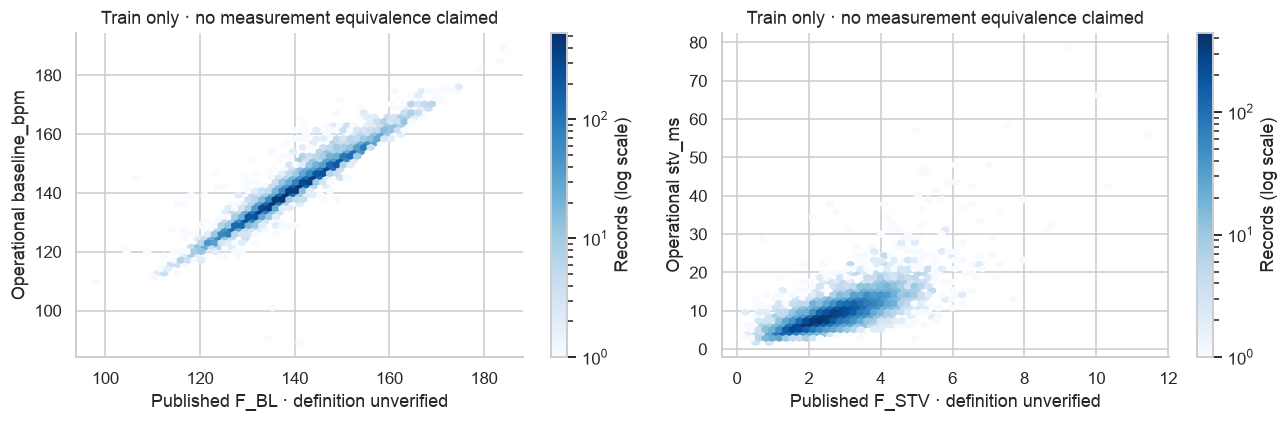

In [17]:
comparison=compare_published_train(measurements)
display(comparison.round(3))
published=pd.read_parquet(SOURCE/'published_features_quarantined.parquet')
paired=train.merge(published[['record_id','F_BL','F_STV']],on='record_id',validate='one_to_one')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,own,pub in zip(axes,['baseline_bpm','stv_ms'],['F_BL','F_STV']):
    z=paired[[own,pub]].dropna()
    hexplot=ax.hexbin(z[pub],z[own],gridsize=60,mincnt=1,cmap='Blues',norm=LogNorm())
    fig.colorbar(hexplot,ax=ax,label='Records (log scale)')
    ax.set(xlabel=f'Published {pub} · definition unverified',ylabel=f'Operational {own}',title='Train only · no measurement equivalence claimed')
fig.tight_layout();show_save('07_published_comparison.png')


### Ваш бланк → числа → производные признаки без сигнала

Ниже используется **ручная транскрипция** прикреплённого примера. Это проверяет обработчик текста, не точность OCR фотографии. Парсер сохраняет строку-источник, не захватывает нормативные числа в скобках, отделяет заключения и требует подтверждения. Неизвестный прибор остаётся неизвестным. «Потеря 8.5%» не позволяет восстановить интервалы потерь; ВКИ не заменяется соседней разностью JNU.

In [19]:
parsed,example,audit=example_report_outputs()
contract=write_contracts()
display(pd.DataFrame(parsed['evidence']))
display(example[['acc15_per_10min','dec15_per_10min','high_variation_fraction','baseline_rr_ms','nominal_nonlost_min','small_acc10_15_count']].round(4))
display(pd.DataFrame({'Требует проверки':audit['issues']}))
print('Не вошло в признаки:',parsed['unparsed_lines'])
print('Клинический риск:',audit['clinical_risk'],'; подтверждённый перенос прибора:',audit['vendor_bridge_validated'])
from src.features.ctg_report_contract import prepare_report,evaluate_report
unverified_input,input_audit=prepare_report(parsed['measurements'],'report5')
display(unverified_input)
display(pd.DataFrame({'Отказ до модели':input_audit['blockers']}))
print('Неизвестные определения не превращаются в NaN, который затем интерпретируется моделью.')


Не вошло в признаки: ['Оценка КТГ плода 1 (Пользовательская)', '8 из 8 параметров в норме']
Клинический риск: None ; подтверждённый перенос прибора: False
Неизвестные определения не превращаются в NaN, который затем интерпретируется моделью.


,field,value,line
0,duration_min,17.0,"Время анализа 17,0 (10–60) мин"
1,signal_loss_pct,8.5,"Потери сигнала 8,5 %"
2,baseline_bpm,131.4,"Базальная ЧСС 131,4 (115–160) BPM"
3,acc10_count,5.0,Акцелерации >10 BPM и 15 с 5
4,acc15_count,1.0,Акцелерации >15 BPM и 15 с ✓ 1 (≥1)
5,dec15_count,0.0,Децелерации >15 BPM и 15 с 0
6,dec20lost_count,0.0,Децелерации >20 ударов ✓ 0 (≤0)
7,high_variation_min,13.0,Высокая вариабельность ✓ 13 (≥3) мин
8,low_variation_min,0.0,Низкая вариабельность 0 мин
9,sinusoidal_min,0.0,Синусоидальный ритм ✓ 0 (≤0) мин


,acc15_per_10min,dec15_per_10min,high_variation_fraction,baseline_rr_ms,nominal_nonlost_min,small_acc10_15_count
0,0.5882,0.0,0.7647,456.621,15.555,NaN


,Требует проверки
0,Unknown device
1,Unknown software_version
2,Report transcription not confirmed
3,Measurement algorithms unverified


,baseline_bpm,acc15_per_10min,dec15_per_10min,stv_ms,amplitude_bpm
0,131.4,0.588235,0.0,7.6,14.1


,Отказ до модели
0,transcription_unconfirmed
1,antenatal_context_unconfirmed
2,duration_not_validated_30min
3,measurement_bridge_unconfirmed
4,stv_3_75s_recipe_unconfirmed
5,amplitude_recipe_unconfirmed
6,event_denominator_unconfirmed


### Независимые проверки и экспорт

Проверяются ID/полнота, fitted median/IQR против независимого расчёта, отсутствие fit на validation/test, маски всех полей и сохранённые необученные шаблоны. Исходные X с NaN нужны для CatBoost и fold-local обработки. Готовые масштабированные матрицы — только reference export; **не вход в nested CV**.

Числа редких исходов и групповые границы взяты из неизменённой подготовки 01. Метки отсутствуют во всех новых матрицах X. Отдельная модель по клиническому исходу требует разрешения противоречий цели и проверки времени КТГ относительно родов.

In [21]:
receipt=validate_exports(measurements)
display(pd.DataFrame(receipt['profiles']))
display(pd.DataFrame({'version':receipt['environment']}))
print('Сохранено:',DEST.relative_to(ROOT))
print('Шаблоны и обученные преобразования:',MODELS.relative_to(ROOT))
print('Финальная научная/клиническая валидация:',receipt['clinical_validation'])


Сохранено: data/processed/jnu_ctg/report_features_v1
Шаблоны и обученные преобразования: models/exported/jnu_ctg/report_features_v1
Финальная научная/клиническая валидация: False


,profile,train_only,median_verified,iqr_verified,all_column_missing_masks,template_unfitted
0,minimal,True,True,True,True,True
1,variability,True,True,True,True,True
2,sonomed_fields,True,True,True,True,True
3,mfmon_fields,True,True,True,True,True
4,mak_fields,True,True,True,True,True


,version
python,3.11.9
numpy,2.4.6
pandas,2.3.3
sklearn,1.9.1


## Takeaways

1. Для приложения основной путь — **несколько моделей по доступным полям отчёта**: минимальный набор, вариабельность и расширенные профили. Четыре семейства определений приборов нельзя незаметно смешать в один STV/LTV.
2. Код позволяет извлечь много исследовательских характеристик, но в deployable X входят только реально доступные поля. Шевеления/ВКИ/синусоидальная длительность не создаются из отсутствующего канала. Счётчик ноль и неизвестный счётчик различаются.
3. Маски, базальная линия и длительность изменяют измерения; точные изменения видны выше и сохранены в таблицах. Выбор версии нельзя оправдывать лучшей test-accuracy. Нужны экспертные аннотации событий или парные измерения.
4. 30-минутную FIGO-метку нельзя автоматически переносить на 10–17-минутное окно. Нельзя по бинарной разметке JNU научить различать suspect и pathologic без новых меток.
Исправленные классификаторы выполнены в 03, проверка — в 04. Дальнейший этап — независимые размеченные бланки и подтверждение измерений; клинический исход остаётся отдельной целью.

**Границы обзора:** первоисточники и уровень доступа перечислены в [методах](REPORT_FEATURE_METHODS.md). Полные закрытые формулы устройств, точность OCR и клиническая валидация не получены. Это рабочая исследовательская подготовка и контракт входа, а не медицинский анализатор.

## Дополнение после экспертного ревью

In [24]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
REVIEW=ROOT/'research/reviews/ctg_20261017'
UCI=ROOT/'research/experiments/ctg_uci/reviewed_v3'
JNU=ROOT/'research/experiments/jnu_ctg/reviewed_v2'
FIGURES=REVIEW/'figures';FIGURES.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',170)
sns.set_theme(style='whitegrid',font_scale=1.0)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
COLORS={'linear':'#009e73','spline':'#d55e00','catboost':'#0072b2'}
def save_show(name):
    plt.gcf().savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    plt.show()


### Амплитуда: исключение акцелераций на тех же минутах

,record_id,figo_label,eligible_minutes_before,common_eligible_minutes,range_before_same_minutes_bpm,range_after_acceleration_exclusion_bpm,method
0,31837_1_210208000001,0.0,30,29,21.690,20.655,same eligible minutes; remove acceleration spans and 5s margins; require >=30s retained original samples
1,39937_1_210208000001,1.0,16,14,17.357,15.214,same eligible minutes; remove acceleration spans and 5s margins; require >=30s retained original samples
2,15176_1_210208000001,1.0,30,27,36.481,36.148,same eligible minutes; remove acceleration spans and 5s margins; require >=30s retained original samples
3,35970_1_210208000001,1.0,20,18,20.222,20.222,same eligible minutes; remove acceleration spans and 5s margins; require >=30s retained original samples
4,20991_1_210208000001,1.0,30,26,30.038,28.423,same eligible minutes; remove acceleration spans and 5s margins; require >=30s retained original samples
5,21947_1_210208000001,1.0,20,15,19.000,14.533,same eligible minutes; remove acceleration spans and 5s margins; require >=30s retained original samples
6,7409_1_210208000001,0.0,25,20,10.650,10.050,same eligible minutes; remove acceleration spans and 5s margins; require >=30s retained original samples
7,40121_1_210208000001,1.0,20,16,8.625,8.625,same eligible minutes; remove acceleration spans and 5s margins; require >=30s retained original samples
8,34968_1_210208000001,0.0,30,27,17.333,13.889,same eligible minutes; remove acceleration spans and 5s margins; require >=30s retained original samples
9,34017_1_210208000001,0.0,20,19,24.789,24.263,same eligible minutes; remove acceleration spans and 5s margins; require >=30s retained original samples


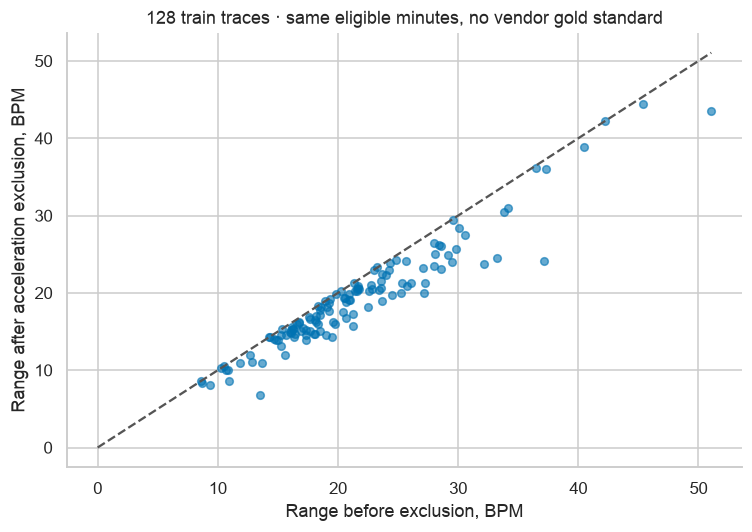

In [26]:
from src.features.jnu_review_detector_probe import controlled_amplitude_probe
probe=controlled_amplitude_probe();display(probe.head(12).round(3))
fig,ax=plt.subplots(figsize=(7,5));ax.scatter(probe.range_before_same_minutes_bpm,probe.range_after_acceleration_exclusion_bpm,s=25,color='#0072b2',alpha=.6)
limit=np.nanmax(probe[['range_before_same_minutes_bpm','range_after_acceleration_exclusion_bpm']].to_numpy());ax.plot([0,limit],[0,limit],'--',color='#555555')
ax.set(xlabel='Range before exclusion, BPM',ylabel='Range after acceleration exclusion, BPM',title='128 train traces · same eligible minutes, no vendor gold standard')
fig.tight_layout();save_show('jnu02_amplitude_definition_probe.png')


### Одна единица и охват строгих профилей

In [28]:
from src.features.ctg_report_contract import PROFILES
from src.training.jnu_review_experiment import load_data,eligible
cohort=load_data()
display(pd.DataFrame([{'profile':p,'fields':len(cols),'complete':int(eligible(cohort,p).sum()),'source_records':len(cohort),'columns':', '.join(cols)} for p,cols in PROFILES.items()]))
display(pd.read_csv(REVIEW/'jnu_missingness_by_class.csv'))
display(pd.read_csv(REVIEW/'jnu_low_high_variation_support.csv').round(4))


,profile,fields,complete,source_records,columns
0,core3,3,20743,20769,"baseline_bpm, acc15_per_10min, dec15_per_10min"
1,report5,5,20726,20769,"baseline_bpm, acc15_per_10min, dec15_per_10min, stv_ms, amplitude_bpm"
2,report7,7,20726,20769,"baseline_bpm, acc15_per_10min, dec15_per_10min, stv_ms, amplitude_bpm, acc10_per_10min, dec20lost_per_10min"
3,report4s5,5,20726,20769,"baseline_bpm, acc15_per_10min, dec15_per_10min, stv_4s_ms, amplitude_bpm"


,split,feature,records,patients,abnormal
0,test,baseline_bpm,13,12,8
1,test,stv_ms,15,14,9
2,test,stv_4s_ms,15,14,9
3,test,amplitude_bpm,14,13,9
4,train,baseline_bpm,8,8,8
5,train,stv_ms,22,22,22
6,train,stv_4s_ms,22,22,22
7,train,amplitude_bpm,18,18,18
8,validation,baseline_bpm,5,5,5
9,validation,stv_ms,6,6,5


,feature,bin,records,patients,abnormal_fraction
0,stv_ms,"[-inf, 4.0)",298,288,0.5302
1,stv_ms,"[4.0, 15.0)",11531,7197,0.5182
2,stv_ms,"[15.0, inf)",613,565,0.9021
3,amplitude_bpm,"[-inf, 10.0)",108,107,0.4074
4,amplitude_bpm,"[10.0, 30.0)",10560,6859,0.4805
5,amplitude_bpm,"[30.0, inf)",1778,1505,0.8841


Minute-range включает акцелерации по операционному определению v1; он не переименовывается в доказанную амплитуду прибора. Baseline-only кандидат также не имеет экспертного эталона и не заменяет основной признак по FIGO-accuracy. Частоты событий сохраняют знаменатель полной записи: поправка на nonlost time не восстанавливает цензурированные события. Длительность 30 min проверяется как область применения, а не бесполезная константа X.


## Takeaways

Цель — морфологическая метка normal/abnormal JNU. Она не заменяет клинический исход или полные критерии Доуза–Редмана. Совместимость с российским прибором не подтверждена; общий вход приложения возвращает отказ до модели. Сырые сигналы нужны только для исследования измерений, не обязательны для будущего приложения.
